# CodeGuard AI · Experiment 05: Train and evaluate the Python vulnerability model

**Goal:** train the model the scanner will use, choose it fairly, test it once, and save it with a model card.

**Steps**
1. Load the clean Python data (Experiment 04)
2. Split by repository
3. Features: TF-IDF on Python tokens
4. Compare five models with grouped cross-validation
5. Pick a decision threshold (on training data only)
6. Final test: scores, confusion matrix, ROC/PR curves, calibration
7. Recall per CWE type
8. Error analysis: what does it miss, what does it wrongly flag?
9. Which tokens does it rely on?
10. Save the model and its model card

In [1]:
import json
import time
import warnings
from datetime import date
from pathlib import Path

import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import sklearn

from sklearn.model_selection import GroupShuffleSplit, GroupKFold, cross_validate, cross_val_predict
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.pipeline import make_pipeline
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.svm import LinearSVC
from sklearn.calibration import CalibratedClassifierCV, CalibrationDisplay
from sklearn.ensemble import RandomForestClassifier
from xgboost import XGBClassifier
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score, roc_auc_score,
                             average_precision_score, confusion_matrix, ConfusionMatrixDisplay,
                             RocCurveDisplay, PrecisionRecallDisplay, precision_recall_curve)

warnings.filterwarnings("ignore")
SEED = 42
ART = Path("../artifacts")

## Step 1: Load

In [2]:
df = pd.read_csv("../datasets/processed/python_functions_clean.csv")
X, y, groups = df["func"], df["target"], df["repo_url"]
print("Methods:", len(df), "| repositories:", groups.nunique())
print(y.value_counts().rename({0: "Fixed / safe", 1: "Vulnerable"}))

Methods: 6627 | repositories: 425
target
Fixed / safe    4255
Vulnerable      2372
Name: count, dtype: int64


## Step 2: Split by repository

Every method from one repository goes to the same side. This keeps each vulnerable/fixed pair together and stops the model from recognising a project's style.

In [3]:
splitter = GroupShuffleSplit(n_splits=1, test_size=0.2, random_state=SEED)
train_idx, test_idx = next(splitter.split(X, y, groups))
X_train, X_test = X.iloc[train_idx], X.iloc[test_idx]
y_train, y_test = y.iloc[train_idx], y.iloc[test_idx]
groups_train = groups.iloc[train_idx]
print(f"Training: {len(X_train)} ({y_train.mean():.0%} vulnerable) | Test: {len(X_test)} ({y_test.mean():.0%} vulnerable)")
print("Repositories in both:", len(set(groups_train) & set(groups.iloc[test_idx])))

Training: 5169 (35% vulnerable) | Test: 1458 (37% vulnerable)
Repositories in both: 0


## Step 3: Features

Python code is split into identifiers **and** symbols, because symbols matter in security code (`%` string formatting, `+` concatenation, `=True`). We use single tokens and pairs of neighbouring tokens.

In [4]:
TOKEN_PATTERN = r"[A-Za-z_]\w*|\d+|==|!=|<=|>=|\*\*|[%+\-*/=<>()\[\]{}.,:'\"]"

def make_tfidf():
    return TfidfVectorizer(token_pattern=TOKEN_PATTERN, lowercase=False, ngram_range=(1, 2),
                           max_features=20000, min_df=2, sublinear_tf=True)

print(make_tfidf().build_analyzer()("subprocess.call('ls ' + x, shell=True)")[:12])

['subprocess', '.', 'call', '(', "'", 'ls', "'", '+', 'x', ',', 'shell', '=']


## Step 4: Compare models (training data only, 5-fold grouped CV)

Same definitions as Experiment 03. The Linear SVM is wrapped in **calibration** so it also returns probabilities, which the scanner needs.

In [5]:
pos_weight = (y_train == 0).sum() / max((y_train == 1).sum(), 1)
models = {
    "Baseline (majority)": DummyClassifier(strategy="most_frequent"),
    "Logistic Regression": LogisticRegression(max_iter=3000, class_weight="balanced", C=1.0),
    "Linear SVM (calibrated)": CalibratedClassifierCV(LinearSVC(C=0.5, class_weight="balanced"), cv=3),
    "Random Forest": RandomForestClassifier(n_estimators=300, class_weight="balanced", min_samples_leaf=2,
                                            random_state=SEED, n_jobs=-1),
    "XGBoost": XGBClassifier(n_estimators=300, max_depth=6, learning_rate=0.1, tree_method="hist",
                             scale_pos_weight=pos_weight, eval_metric="logloss", random_state=SEED, n_jobs=-1),
}
scoring = {"accuracy": "accuracy", "precision": "precision", "recall": "recall", "f1": "f1",
           "roc_auc": "roc_auc", "pr_auc": "average_precision"}
cv = GroupKFold(n_splits=5)

rows = []
for name, model in models.items():
    start = time.time()
    s = cross_validate(make_pipeline(make_tfidf(), model), X_train, y_train, groups=groups_train,
                       cv=cv, scoring=scoring)
    rows.append({"Model": name, **{m: s[f"test_{m}"].mean() for m in scoring},
                 "F1 std": s["test_f1"].std(), "Seconds": time.time() - start})
comparison = pd.DataFrame(rows).set_index("Model").round(3)
comparison

,accuracy,precision,recall,f1,roc_auc,pr_auc,F1 std,Seconds
Model,,,,,,,,
Baseline (majority),0.647,0.000,0.000,0.000,0.500,0.353,0.000,29.808
Logistic Regression,0.596,0.431,0.433,0.425,0.586,0.429,0.047,31.478
Linear SVM (calibrated),0.647,0.000,0.000,0.000,0.535,0.395,0.000,31.641
Random Forest,0.651,0.532,0.076,0.130,0.576,0.425,0.051,48.462
XGBoost,0.598,0.420,0.349,0.375,0.562,0.414,0.040,182.009


In [6]:
best_name = comparison.drop(index="Baseline (majority)")["pr_auc"].idxmax()
print("Chosen by cross-validated PR-AUC:", best_name)

Chosen by cross-validated PR-AUC: Logistic Regression


We choose by **PR-AUC** because the scanner uses the *score* (and a threshold we pick next), not a fixed 0.5 cut-off. PR-AUC measures score quality across all thresholds and focuses on the vulnerable class.

## Step 5: Pick the decision threshold (training data only)

We get out-of-fold scores on the training set and choose the threshold with the best F1. The test set is still untouched.

In [7]:
oof = cross_val_predict(make_pipeline(make_tfidf(), models[best_name]), X_train, y_train,
                        groups=groups_train, cv=cv, method="predict_proba")[:, 1]
prec, rec, thr = precision_recall_curve(y_train, oof)
f1s = 2 * prec[:-1] * rec[:-1] / np.clip(prec[:-1] + rec[:-1], 1e-9, None)
threshold = float(round(thr[np.argmax(f1s)], 3))
print("Chosen threshold:", threshold, "| out-of-fold F1 at that threshold:", round(f1s.max(), 3))

Chosen threshold: 0.311 | out-of-fold F1 at that threshold: 0.525


## Step 6: Final exam on the test set (run once)

In [8]:
final_model = make_pipeline(make_tfidf(), models[best_name]).fit(X_train, y_train)
score = final_model.predict_proba(X_test)[:, 1]
pred = (score >= threshold).astype(int)
tn, fp, fn, tp = confusion_matrix(y_test, pred).ravel()
test_metrics = {
    "test_size": int(len(y_test)), "accuracy": accuracy_score(y_test, pred),
    "precision": precision_score(y_test, pred), "recall": recall_score(y_test, pred),
    "f1": f1_score(y_test, pred), "roc_auc": roc_auc_score(y_test, score),
    "pr_auc": average_precision_score(y_test, score), "false_positive_rate": fp / (fp + tn),
    "baseline_accuracy": float(max(y_test.mean(), 1 - y_test.mean())), "baseline_pr_auc": float(y_test.mean()),
}
test_metrics = {k: (round(v, 3) if isinstance(v, float) else v) for k, v in test_metrics.items()}
pd.Series(test_metrics)

test_size              1458.000
accuracy                  0.441
precision                 0.392
recall                    0.899
f1                        0.546
roc_auc                   0.553
pr_auc                    0.417
false_positive_rate       0.833
baseline_accuracy         0.626
baseline_pr_auc           0.374
dtype: float64

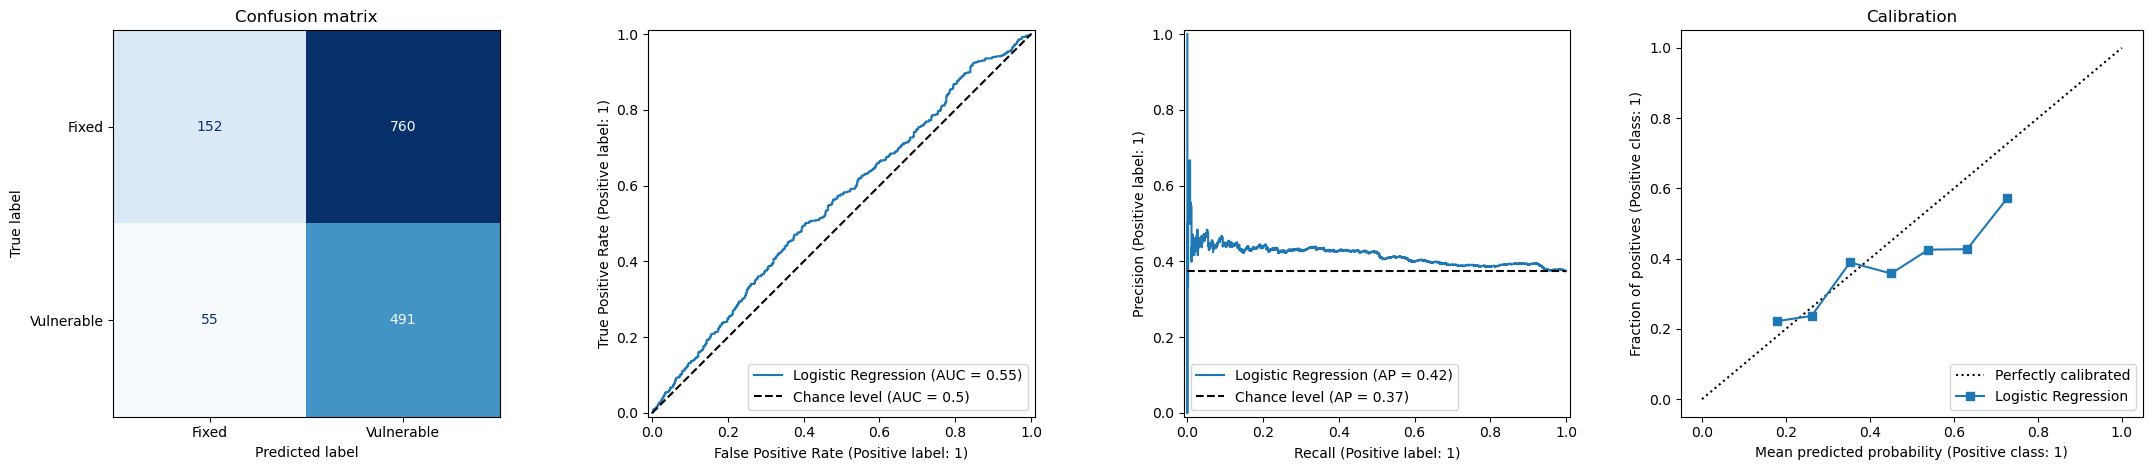

In [9]:
fig, axes = plt.subplots(1, 4, figsize=(22, 4.8))
ConfusionMatrixDisplay.from_predictions(y_test, pred, display_labels=["Fixed", "Vulnerable"], cmap="Blues",
                                        ax=axes[0], colorbar=False)
axes[0].set_title("Confusion matrix")
RocCurveDisplay.from_predictions(y_test, score, ax=axes[1], name=best_name, plot_chance_level=True)
PrecisionRecallDisplay.from_predictions(y_test, score, ax=axes[2], name=best_name, plot_chance_level=True)
CalibrationDisplay.from_predictions(y_test, score, n_bins=10, ax=axes[3], name=best_name)
axes[3].set_title("Calibration")
plt.tight_layout()
plt.savefig(ART / "figures" / "python_test_curves.png", dpi=120)
plt.show()

**Calibration decides how the app shows the score.** If points sit far from the diagonal, the score is not a trustworthy confidence, and the app must keep calling it a "resemblance score", not a probability.

## Step 7: Recall per CWE type

In [10]:
test_df = df.iloc[test_idx].assign(pred=pred, score=score)
vuln = test_df[test_df["target"] == 1].assign(cwe=lambda d: d["cwe_id"].str.split(",")).explode("cwe")
per_cwe = vuln.groupby("cwe")["pred"].agg(["size", "mean"]).rename(columns={"size": "vulnerable methods", "mean": "recall"})
per_cwe[per_cwe["vulnerable methods"] >= 10].sort_values("recall", ascending=False).round(2)

,vulnerable methods,recall
cwe,,
CWE-200,10,1.00
CWE-29,18,1.00
CWE-94,23,1.00
CWE-863,14,1.00
CWE-78,10,1.00
NVD-CWE-Other,13,1.00
CWE-918,16,1.00
CWE-22,63,0.98
NVD-CWE-noinfo,134,0.96


## Step 8: Error analysis

In [11]:
missed = test_df[(test_df["target"] == 1) & (test_df["pred"] == 0)].nsmallest(5, "score")
false_alarms = test_df[(test_df["target"] == 0) & (test_df["pred"] == 1)].nlargest(5, "score")
for title, rows in [("MISSED vulnerable methods (lowest scores)", missed), ("FALSE ALARMS (highest scores)", false_alarms)]:
    print("=" * 20, title, "=" * 20)
    for _, r in rows.iterrows():
        print(f"score {r['score']:.2f} | {r['cwe_id']} | {r['method_name']}")
        print(r["func"][:300], "\n")

==================== MISSED vulnerable methods (lowest scores) ====================
score 0.16 | CWE-444 | test_received_headers_finished_expect_continue_true
    def test_received_headers_finished_expect_continue_true(self):
        inst, sock, map = self._makeOneWithMap()
        inst.server = DummyServer()
        preq = DummyParser()
        inst.request = preq
        preq.expect_continue = True
        preq.headers_finished = True
        preq.compl 

score 0.16 | CWE-359 | test_attach_subscription_available_with_activation_key
    def test_attach_subscription_available_with_activation_key(self):
        self.assertEqual(subscription.attach_subscription(), True)
        self.assertEqual(len(subscription.loggerinst.info_msgs), 1) 

score 0.19 | CWE-444 | test_received_headers_finished_expect_continue_true_sent_true
    def test_received_headers_finished_expect_continue_true_sent_true(self):
        inst, sock, map = self._makeOneWithMap()
        inst.server = DummyServer()
      

**What we found:** the most confidently *missed* vulnerable methods are mostly **test methods** (for example waitress `test_received_headers_*`, CWE-444). They are labelled vulnerable only because the fix commit edited them; they are not unsafe code. This is label noise the model cannot (and should not) learn.

## Step 9: Which tokens does it rely on?

In [12]:
est = final_model[-1]
names = final_model[0].get_feature_names_out()
if hasattr(est, "coef_"):
    weights = pd.Series(np.ravel(est.coef_), index=names)
elif hasattr(est, "calibrated_classifiers_"):
    weights = pd.Series(np.mean([np.ravel(c.estimator.coef_) for c in est.calibrated_classifiers_], axis=0), index=names)
else:
    weights = pd.Series(est.feature_importances_, index=names)
print("Top tokens pointing to VULNERABLE:")
print(weights.nlargest(15).round(3).to_string())
print()
print("Top tokens pointing to FIXED:")
print(weights.nsmallest(15).round(3).to_string())

Top tokens pointing to VULNERABLE:
http_client =      1.418
_path              1.402
add                1.401
http_client        1.349
. _path            1.325
add (              1.203
. add              1.173
, http_client      1.156
request .          1.057
mark_safe          1.016
mark_safe (        1.016
return redirect    1.013
redirect (         0.991
None               0.898
= self             0.872

Top tokens pointing to FIXED:
commit (                   -2.414
. commit                   -2.382
commit                     -1.982
federation_http_client     -1.318
federation_http_client =   -1.305
safe_redirect              -1.194
safe_redirect (            -1.194
return safe_redirect       -1.145
unsanitized                -1.123
field                      -1.115
. unsanitized              -1.082
_filesystem_path           -1.077
filesystem_path            -1.056
. _filesystem_path         -1.004
*                          -0.983


**Be careful:** check whether top tokens are security concepts or just project-specific names.

## Step 10: Save the model and its model card

The scanner loads `artifacts/model/python_vuln_model.joblib` and reads the threshold and metrics from `model_card.json`.

In [13]:
(ART / "model").mkdir(parents=True, exist_ok=True)
joblib.dump(final_model, ART / "model" / "python_vuln_model.joblib")
card = {
    "model_version": f"py-tfidf-{best_name.split()[0].lower()}-{date.today():%Y%m%d}",
    "language": "python",
    "algorithm": best_name,
    "features": "TF-IDF on Python identifier and symbol tokens, 1-2 grams, 20k max features",
    "training_data": "CVEfixes Python methods (before fix = 1, after fix = 0), cleaned in experiment 04",
    "split": "GroupShuffleSplit by repository 80/20 (seed 42); model chosen by 5-fold GroupKFold PR-AUC",
    "train_size": int(len(X_train)), "test_size": int(len(X_test)),
    "threshold": threshold, "threshold_method": "max F1 on out-of-fold training predictions",
    "cross_validation": comparison.reset_index().to_dict(orient="records"),
    "test_metrics": test_metrics,
    "sklearn_version": sklearn.__version__,
    "created": date.today().isoformat(),
    "limitations": [
        "Scores whole methods; cannot point to the exact unsafe line.",
        "Score is a resemblance to vulnerable training examples, not a probability of exploitability.",
        "Trained on CVE-fix commits whose labels contain noise.",
        "Python only.",
    ],
}
(ART / "model" / "model_card.json").write_text(json.dumps(card, indent=2), encoding="utf-8")
(ART / "metrics" / "python_results.json").write_text(json.dumps(card, indent=2), encoding="utf-8")
print("Saved model, model card and metrics.")

Saved model, model card and metrics.


## Conclusion

| Test set (1,458 methods, 0 shared repositories) | Accuracy | Precision | Recall | F1 | ROC-AUC | PR-AUC | False-positive rate |
|---|---|---|---|---|---|---|---|
| Baseline (always "fixed") | 0.626 | — | 0 | 0 | 0.5 | 0.374 | 0 |
| **Logistic Regression, threshold 0.311** | 0.441 | 0.392 | 0.899 | 0.546 | 0.553 | 0.417 | **0.833** |

1. **Model choice:** Logistic Regression had the best cross-validated PR-AUC (0.429; XGBoost 0.414, Random Forest 0.425). The calibrated Linear SVM never predicted "vulnerable" at 0.5. All models were close to chance (ROC-AUC 0.54–0.59).
2. **Threshold:** maximising F1 on out-of-fold predictions chose 0.311. Because the scores barely separate the classes, that threshold flags almost everything: 90% recall but 83% of safe methods flagged. In the scanner this means many "unconfirmed" ML findings on safe code.
3. **Calibration:** scores are not trustworthy probabilities; the app must keep calling them "resemblance scores".
4. **Why it is weak:** vulnerable and fixed versions are near-identical; labels are noisy (unchanged methods and edited tests labelled vulnerable); and new test methods labelled "fixed" create a shortcut (top "fixed" tokens include `commit`, `safe_redirect`, `unsanitized`, test words). Some tokens are real security signals (`mark_safe`, `redirect` → vulnerable; `safe_redirect` → fixed), which is encouraging.
5. **Honest bottom line:** like Devign, a TF-IDF model on real CVE-fix data is only slightly better than chance at ranking (ROC-AUC 0.55). Bandit remains the scanner's main detector; the ML score is supporting information only.

**Next steps (version 2):** keep only methods that exist both before and after the fix (true pairs), drop test code, and choose the scanner's threshold with a false-positive cap on training data. Report the v2 test result separately and note that the test set has then been used twice. CodeBERT (Experiment 06) can be compared on the same split.